In [ ]:
!wget -q -O 4ey7.pdb "https://files.rcsb.org/download/4EY7.pdb"
!ls -lh 4ey7.pdb
!head -3 4ey7.pdb

!grep "^HETATM" 4ey7.pdb | cut -c18-20 | sort | uniq -c | sort -rn | head -10

!grep -E "^REMARK   2 RESOLUTION|^TITLE" 4ey7.pdb

-rw-r--r-- 1 root root 776K Sep 25  2025 4ey7.pdb
HEADER    HYDROLASE/HYDROLASE INHIBITOR           01-MAY-12   4EY7              
TITLE     CRYSTAL STRUCTURE OF RECOMBINANT HUMAN ACETYLCHOLINESTERASE IN COMPLEX
TITLE    2 WITH DONEPEZIL                                                       
    552 HOH
     70 NAG
     56 E20
     20 FUC
     12 EDO
      8 NO3
TITLE     CRYSTAL STRUCTURE OF RECOMBINANT HUMAN ACETYLCHOLINESTERASE IN COMPLEX
TITLE    2 WITH DONEPEZIL                                                       
REMARK   2 RESOLUTION.    2.35 ANGSTROMS.                                       


In [ ]:
!pip -q install condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:16
🔁 Restarting kernel...


In [ ]:
!mamba install -q -y -c conda-forge smina openbabel rdkit pdbfixer openmm
!smina --version
!obabel -V
python_check = __import__("rdkit").__version__
print("rdkit", python_check)

error    libmamba Could not solve for environment specs
    The following packages are incompatible
    ├─ openbabel =* * is installable with the potential options
    │  ├─ openbabel 3.2.1 would require
    │  │  └─ libzlib >=1.3.2,<2.0a0 * with the potential options
    │  │     ├─ libzlib 1.3.2 would require
    │  │     │  └─ zlib ==1.3.2 *_2, which can be installed;
    │  │     └─ libzlib 1.3.2 would require
    │  │        └─ zlib ==1.3.2 *_3, which can be installed;
    │  ├─ openbabel [3.1.1|3.2.1] would require
    │  │  └─ python >=3.10,<3.11.0a0 *, which can be installed;
    │  ├─ openbabel [3.1.1|3.2.1] would require
    │  │  └─ python >=3.11,<3.12.0a0 *, which can be installed;
    │  ├─ openbabel [3.1.1|3.2.1] would require
    │  │  └─ python [>=3.12,<3.13.0a0 *|>=3.12.0rc3,<3.13.0a0 *], which can be installed;
    │  ├─ openbabel [3.0.0|3.1.0|3.1.1] would require
    │  │  └─ python >=3.8,<3.9.0a0 *, which can be installed;
    │  ├─ openbabel 3.1.1 would require
   

ModuleNotFoundError: No module named 'rdkit'

In [ ]:
!mamba install -q -y -c conda-forge smina openbabel rdkit pdbfixer openmm
!smina --version
!obabel -V
python_check = __import__("rdkit").__version__
print("rdkit", python_check)

error    libmamba Could not solve for environment specs
    The following packages are incompatible
    ├─ openbabel =* * is installable with the potential options
    │  ├─ openbabel 3.2.1 would require
    │  │  └─ libzlib >=1.3.2,<2.0a0 * with the potential options
    │  │     ├─ libzlib 1.3.2 would require
    │  │     │  └─ zlib ==1.3.2 *_2, which can be installed;
    │  │     └─ libzlib 1.3.2 would require
    │  │        └─ zlib ==1.3.2 *_3, which can be installed;
    │  ├─ openbabel [3.1.1|3.2.1] would require
    │  │  └─ python >=3.10,<3.11.0a0 *, which can be installed;
    │  ├─ openbabel [3.1.1|3.2.1] would require
    │  │  └─ python >=3.11,<3.12.0a0 *, which can be installed;
    │  ├─ openbabel [3.1.1|3.2.1] would require
    │  │  └─ python [>=3.12,<3.13.0a0 *|>=3.12.0rc3,<3.13.0a0 *], which can be installed;
    │  ├─ openbabel [3.0.0|3.1.0|3.1.1] would require
    │  │  └─ python >=3.8,<3.9.0a0 *, which can be installed;
    │  ├─ openbabel 3.1.1 would require
   

ModuleNotFoundError: No module named 'rdkit'

In [ ]:
!mamba create -q -y -n dock -c conda-forge python=3.10 smina openbabel
!conda run -n dock smina --version
!conda run -n dock obabel -V

smina 2020.12.10 conda-forge:b08c07c   Built Jul 15 2025.  Based on AutoDock Vina 1.1.2.
Open Babel 3.1.0 -- Nov 30 2023 -- 20:43:22


In [ ]:
!pip -q install rdkit
import rdkit
print("rdkit", rdkit.__version__)

rdkit 2026.09.1


In [ ]:
!wget -q -O smina https://sourceforge.net/projects/smina/files/smina.static/download
!chmod +x smina
!./smina --version

Smina Oct 15 2019.  Based on AutoDock Vina 1.1.2.


In [ ]:
drop_het = {"HOH", "NAG", "FUC", "EDO", "NO3", "SO4", "CL", "PEG", "MAN", "BMA"}
keep_chain = "A"

prot, lig = [], []
for line in open("4ey7.pdb"):
    rec = line[:6]
    if rec not in ("ATOM  ", "HETATM"):
        continue
    if line[16] not in (" ", "A"):
        continue
    resn, chain = line[17:20].strip(), line[21]
    if chain != keep_chain:
        continue
    if rec == "ATOM  " and resn not in drop_het:
        prot.append(line)
    elif resn == "E20":
        lig.append(line)

with open("receptor_raw.pdb", "w") as f:
    f.writelines(prot); f.write("TER\nEND\n")
with open("ligand_ref.pdb", "w") as f:
    f.writelines(lig); f.write("END\n")

print("атомов белка:", len(prot), "| атомов лиганда:", len(lig))

атомов белка: 4130 | атомов лиганда: 28


In [ ]:
import numpy as np

def xyz(lines):
    return np.array([[float(l[30:38]), float(l[38:46]), float(l[46:54])] for l in lines])

center = xyz([l for l in open("ligand_ref.pdb") if l.startswith("HETATM")]).mean(axis=0)
print("центр лиганда:", center.round(2))

prot_lines = [l for l in open("receptor_raw.pdb") if l.startswith("ATOM")]
resnums = sorted({int(l[22:26]) for l in prot_lines})
ca = {int(l[22:26]): xyz([l])[0] for l in prot_lines if l[12:16].strip() == "CA"}

gaps = [(a, b) for a, b in zip(resnums, resnums[1:]) if b - a > 1]
for a, b in gaps:
    d = min(np.linalg.norm(ca[a] - center), np.linalg.norm(ca[b] - center))
    print(f"разрыв {a}-{b}: пропущено {b - a - 1} остатков, ближайший край в {d:.1f} A от лиганда")
print("всего разрывов:", len(gaps), "| остатков в модели:", len(resnums))

центр лиганда: [-14.11 -43.83  27.67]
разрыв 258-265: пропущено 6 остатков, ближайший край в 29.8 A от лиганда
разрыв 494-498: пропущено 3 остатков, ближайший край в 36.5 A от лиганда
всего разрывов: 2 | остатков в модели: 530


In [ ]:
!conda run -n dock obabel receptor_raw.pdb -O receptor_prep.pdb -p 7.4
!grep -c "^ATOM\|^HETATM" receptor_prep.pdb

*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is receptor_raw.pdb)

1 molecule converted
8148


In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem

smi = "COc1cc2c(cc1OC)C(=O)C(CC1CCN(Cc3ccccc3)CC1)C2"   # CHEMBL502
tmpl = Chem.MolFromSmiles(smi)

m = Chem.AddHs(Chem.MolFromSmiles(smi))
AllChem.EmbedMolecule(m, randomSeed=42)
AllChem.MMFFOptimizeMolecule(m)
Chem.MolToMolFile(m, "ligand_dock.sdf")
print("тяжёлых атомов:", tmpl.GetNumHeavyAtoms(), "| вращаемых связей:",
      AllChem.CalcNumRotatableBonds(tmpl))

тяжёлых атомов: 28 | вращаемых связей: 6


In [ ]:
!conda run -n dock smina -r receptor_prep.pdb -l ligand_dock.sdf \
    --autobox_ligand ligand_ref.pdb --autobox_add 4 \
    --exhaustiveness 16 --num_modes 9 --seed 42 \
    -o redock_poses.sdf --log redock.log
!tail -20 redock.log

   _______  _______ _________ _        _______ 
  (  ____ \(       )\__   __/( (    /|(  ___  )
  | (    \/| () () |   ) (   |  \  ( || (   ) |
  | (_____ | || || |   | |   |   \ | || (___) |
  (_____  )| |(_)| |   | |   | (\ \) ||  ___  |
        ) || |   | |   | |   | | \   || (   ) |
  /\____) || )   ( |___) (___| )  \  || )   ( |
  \_______)|/     \|\_______/|/    )_)|/     \|


smina is based off AutoDock Vina. Please cite appropriately.

Weights      Terms
-0.035579    gauss(o=0,_w=0.5,_c=8)
-0.005156    gauss(o=3,_w=2,_c=8)
0.840245     repulsion(o=0,_c=8)
-0.035069    hydrophobic(g=0.5,_b=1.5,_c=8)
-0.587439    non_dir_h_bond(g=-0.7,_b=0,_c=8)
1.923        num_tors_div

Using random seed: 42

0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
1       

In [ ]:
from rdkit.Chem import rdMolAlign

cryst = Chem.MolFromPDBFile("ligand_ref.pdb", removeHs=True, sanitize=False)
cryst = AllChem.AssignBondOrdersFromTemplate(tmpl, cryst)

poses = [p for p in Chem.SDMolSupplier("redock_poses.sdf", removeHs=True) if p]
for i, p in enumerate(poses, 1):
    score = float(p.GetProp("minimizedAffinity"))
    rmsd = rdMolAlign.CalcRMS(p, cryst)
    print(f"поза {i}: score {score:6.2f} ккал/моль, RMSD {rmsd:5.2f} A")

поза 1: score -11.81 ккал/моль, RMSD  0.80 A
поза 2: score -11.66 ккал/моль, RMSD  1.08 A
поза 3: score -11.49 ккал/моль, RMSD  2.33 A
поза 4: score -11.17 ккал/моль, RMSD  2.86 A
поза 5: score -10.92 ккал/моль, RMSD  8.68 A
поза 6: score -10.87 ккал/моль, RMSD  9.88 A
поза 7: score -10.29 ккал/моль, RMSD  3.28 A
поза 8: score -10.28 ккал/моль, RMSD  9.10 A
поза 9: score -10.14 ккал/моль, RMSD  4.65 A


[10:30:46] WARNING: More than one matching pattern found - picking one

[10:30:46] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:30:46] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:30:46] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:30:46] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:30:46] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:30:46] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:30:46] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:30:46] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:30:46] Warning: molecule is 

In [ ]:
import os, pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
RDLogger.DisableLog("rdApp.*")

URL = "https://raw.githubusercontent.com/cns-biotech/ache-virtual-screening/main/ache_final.csv"
df = pd.read_csv(URL)

sel = pd.concat([df.nlargest(50, "pIC50").assign(label=1),
                 df.nsmallest(50, "pIC50").assign(label=0)], ignore_index=True)
print(sel.groupby("label")[["pIC50", "MW"]].agg(["count", "median", "min", "max"]).round(2))

os.makedirs("ligands", exist_ok=True)
ok, fail = [], []
for _, r in sel.iterrows():
    m = Chem.MolFromSmiles(r.smiles_clean)
    if m is None:
        fail.append(r.molecule_chembl_id); continue
    m = Chem.AddHs(m)
    if AllChem.EmbedMolecule(m, randomSeed=42) != 0:
        fail.append(r.molecule_chembl_id); continue
    AllChem.MMFFOptimizeMolecule(m, maxIters=500)
    Chem.MolToMolFile(m, f"ligands/{r.molecule_chembl_id}.sdf")
    ok.append(r.molecule_chembl_id)

sel.to_csv("screen_set.csv", index=False)
print("подготовлено:", len(ok), "| не удалось:", len(fail), fail)

      pIC50                        MW                        
      count median   min    max count  median     min     max
label                                                        
0        50   3.08  3.00   3.20    50  355.42  114.21  863.27
1        50  10.49  9.57  10.96    50  434.88  230.29  680.89
подготовлено: 99 | не удалось: 1 ['CHEMBL1203984']


In [13]:
import subprocess, time, csv, re

os.makedirs("poses", exist_ok=True)
done = set()
if os.path.exists("screen_scores.csv"):
    done = {row[0] for row in csv.reader(open("screen_scores.csv"))}

f = open("screen_scores.csv", "a", newline="")
w = csv.writer(f)
t0 = time.time()
for i, cid in enumerate(ok, 1):
    if cid in done:
        continue
    out = f"poses/{cid}.sdf"
    subprocess.run(["conda", "run", "-n", "dock", "smina",
                    "-r", "receptor_prep.pdb", "-l", f"ligands/{cid}.sdf",
                    "--autobox_ligand", "ligand_ref.pdb", "--autobox_add", "4",
                    "--exhaustiveness", "8", "--num_modes", "1",
                    "--seed", "42", "-o", out, "--quiet"],
                   capture_output=True, text=True)
    score = None
    if os.path.exists(out):
        m = re.search(r"minimizedAffinity>\s*\n(-?\d+\.?\d*)", open(out).read())
        if m:
            score = float(m.group(1))
    w.writerow([cid, score]); f.flush()
    if i % 10 == 0:
        print(f"{i}/{len(ok)}, прошло {(time.time() - t0) / 60:.1f} мин")
f.close()
print("готово, всего минут:", round((time.time() - t0) / 60, 1))

10/99, прошло 17.4 мин
20/99, прошло 29.9 мин
30/99, прошло 63.5 мин
40/99, прошло 144.1 мин
50/99, прошло 177.0 мин
60/99, прошло 186.7 мин
70/99, прошло 214.8 мин
80/99, прошло 227.0 мин
90/99, прошло 240.4 мин
готово, всего минут: 252.1


In [14]:
import os
print("файлы на месте:", [p for p in ["receptor_prep.pdb", "ligand_ref.pdb", "screen_set.csv"] if os.path.exists(p)])
print("посчитано молекул:", sum(1 for _ in open("screen_scores.csv")) if os.path.exists("screen_scores.csv") else 0)
print("лигандов подготовлено:", len(os.listdir("ligands")) if os.path.exists("ligands") else 0)
!conda run -n dock smina --version

файлы на месте: ['receptor_prep.pdb', 'ligand_ref.pdb', 'screen_set.csv']
посчитано молекул: 99
лигандов подготовлено: 99
smina 2020.12.10 conda-forge:b08c07c   Built Jul 15 2025.  Based on AutoDock Vina 1.1.2.


In [15]:
from google.colab import files
files.download("screen_scores.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import spearmanr

sc = pd.read_csv("screen_scores.csv", header=None, names=["molecule_chembl_id", "score"])
d = pd.read_csv("screen_set.csv").merge(sc, on="molecule_chembl_id").dropna(subset=["score"])

print("молекул с результатом:", len(d))
print("ROC-AUC:", round(roc_auc_score(d.label, -d.score), 3))
print("PR-AUC :", round(average_precision_score(d.label, -d.score), 3),
      "| базовый уровень:", round(d.label.mean(), 3))
print("Spearman score и pIC50:", [round(x, 4) for x in spearmanr(d.score, d.pIC50)])
print("Spearman score и MW   :", [round(x, 4) for x in spearmanr(d.score, d.MW)])
print(d.groupby("label")["score"].agg(["count", "mean", "median", "min", "max"]).round(2))

молекул с результатом: 99
ROC-AUC: 0.766
PR-AUC : 0.799 | базовый уровень: 0.505
Spearman score и pIC50: [np.float64(-0.449), np.float64(0.0)]
Spearman score и MW   : [np.float64(-0.6138), np.float64(0.0)]
       count   mean  median    min   max
label                                   
0         49  -9.37   -9.93 -11.98 -4.39
1         50 -11.08  -11.41 -14.29 -7.66


In [17]:
print(d.nsmallest(5, "score")[["molecule_chembl_id", "score", "pIC50", "MW", "label"]].to_string(index=False))

molecule_chembl_id     score     pIC50      MW  label
     CHEMBL4214707 -14.28559 10.679023 418.880      1
     CHEMBL4217663 -14.24625 10.849244 439.298      1
     CHEMBL4209803 -13.20840 10.869023 398.462      1
     CHEMBL1187434 -13.19151  9.568636 562.154      1
      CHEMBL307004 -12.47442 10.154902 561.601      1


In [18]:
import numpy as np
from rdkit import Chem
from scipy.stats import rankdata

d["heavy"] = [Chem.MolFromSmiles(s).GetNumHeavyAtoms() for s in d.smiles_clean]
d["LE"] = -d.score / d.heavy          # лигандная эффективность

for name, v in [("score", -d.score), ("молекулярная масса", d.MW),
                ("число тяжёлых атомов", d.heavy), ("лигандная эффективность", d.LE)]:
    print(f"ROC-AUC по {name}: {roc_auc_score(d.label, v):.3f}")

for a, b, n in [(d.score, d.pIC50, "score и pIC50"), (d.score, d.MW, "score и MW"),
                (d.MW, d.pIC50, "MW и pIC50")]:
    r = spearmanr(a, b)
    print(f"{n}: rho {r.statistic:.3f}, p {r.pvalue:.2e}")

def partial(x, y, z):
    x, y, z = (rankdata(v) for v in (x, y, z))
    rxy, rxz, ryz = (np.corrcoef(*p)[0, 1] for p in ((x, y), (x, z), (y, z)))
    return (rxy - rxz * ryz) / np.sqrt((1 - rxz**2) * (1 - ryz**2))

print("частная rho score и pIC50 при фиксированной MW:",
      round(partial(d.score, d.pIC50, d.MW), 3))

ROC-AUC по score: 0.766
ROC-AUC по молекулярная масса: 0.730
ROC-AUC по число тяжёлых атомов: 0.723
ROC-AUC по лигандная эффективность: 0.360
score и pIC50: rho -0.449, p 3.14e-06
score и MW: rho -0.614, p 1.42e-11
MW и pIC50: rho 0.242, p 1.57e-02
частная rho score и pIC50 при фиксированной MW: -0.392


In [19]:
coef = np.polyfit(d.heavy, d.score, 1)
d["resid"] = d.score - np.polyval(coef, d.heavy)
print("ROC-AUC по остатку score после вычитания вклада размера:",
      round(roc_auc_score(d.label, -d.resid), 3))

ROC-AUC по остатку score после вычитания вклада размера: 0.64


In [20]:
!mamba install -q -y -n dock -c conda-forge pymol-open-source
!conda run -n dock pymol -cq -d "print('pymol ok')"

PyMOL>print('pymol ok')
pymol ok


In [21]:
open("redock.pml", "w").write("""
load receptor_prep.pdb, rec
load ligand_ref.pdb, cryst
load redock_poses.sdf, redock
set state, 1
hide everything
bg_color white
show cartoon, rec
color grey80, rec
set cartoon_transparency, 0.65
select pocket, byres (polymer within 5 of cryst)
show sticks, pocket and sidechain and not hydro
color palecyan, pocket and elem C
show sticks, cryst and not hydro
show sticks, redock and not hydro
color yellow, cryst and elem C
color magenta, redock and elem C
set ray_shadows, 0
set antialias, 2
orient cryst
zoom cryst, 4
png fig_redock.png, width=1600, height=1200, dpi=300, ray=1
""")
!conda run -n dock pymol -cq redock.pml

COMPND    receptor_raw.pdb
 CmdLoad: "" loaded as "rec".
 CmdLoad: "" loaded as "cryst".
 ObjectMoleculeReadStr: read through molecule 1.
 ObjectMoleculeReadStr: read through molecule 2.
 ObjectMoleculeReadStr: read through molecule 3.
 ObjectMoleculeReadStr: read through molecule 4.
 ObjectMoleculeReadStr: read through molecule 5.
 ObjectMoleculeReadStr: read through molecule 6.
 ObjectMoleculeReadStr: read through molecule 7.
 ObjectMoleculeReadStr: read through molecule 8.
 ObjectMoleculeReadStr: read through molecule 9.
 CmdLoad: "redock_poses.sdf" loaded as "redock".
 Setting: state set to 1.
 Executive: Colored 8148 atoms and 1 object.
 Setting: cartoon_transparency set to 0.65000.
 Selector: selection "pocket" defined with 840 atoms.
 Executive: Colored 303 atoms.
 Executive: Colored 24 atoms.
 Executive: Colored 216 atoms.
 Setting: ray_shadow set to off.
 Setting: antialias set to 2.
 Ray: render time: 21.15 sec. = 170.3 frames/hour (21.15 sec. accum.).
 ScenePNG: wrote 1600x1

COMPND    receptor_raw.pdb
 CmdLoad: "" loaded as "rec".
 CmdLoad: "poses/CHEMBL4214707.sdf" loaded as "hit".
 Executive: Colored 8148 atoms and 1 object.
 Setting: transparency set to 0.25000.
 Executive: Colored 24 atoms.
 Setting: ray_shadow set to off.
 Setting: antialias set to 2.
 Ray: render time: 49.22 sec. = 73.1 frames/hour (49.22 sec. accum.).
 ScenePNG: wrote 1600x1200 pixel image to file "fig_tophit.png".
PyMOL>load receptor_prep.pdb, rec
PyMOL>load poses/CHEMBL4214707.sdf, hit
PyMOL>hide everything
PyMOL>bg_color white
PyMOL>show surface, rec
PyMOL>color grey70, rec
PyMOL>set transparency, 0.25
PyMOL>show sticks, hit and not hydro
PyMOL>color orange, hit and elem C
PyMOL>set ray_shadows, 0
PyMOL>set antialias, 2
PyMOL>orient hit
PyMOL>zoom hit, 6
PyMOL>png fig_tophit.png, width=1600, height=1200, dpi=300, ray=1


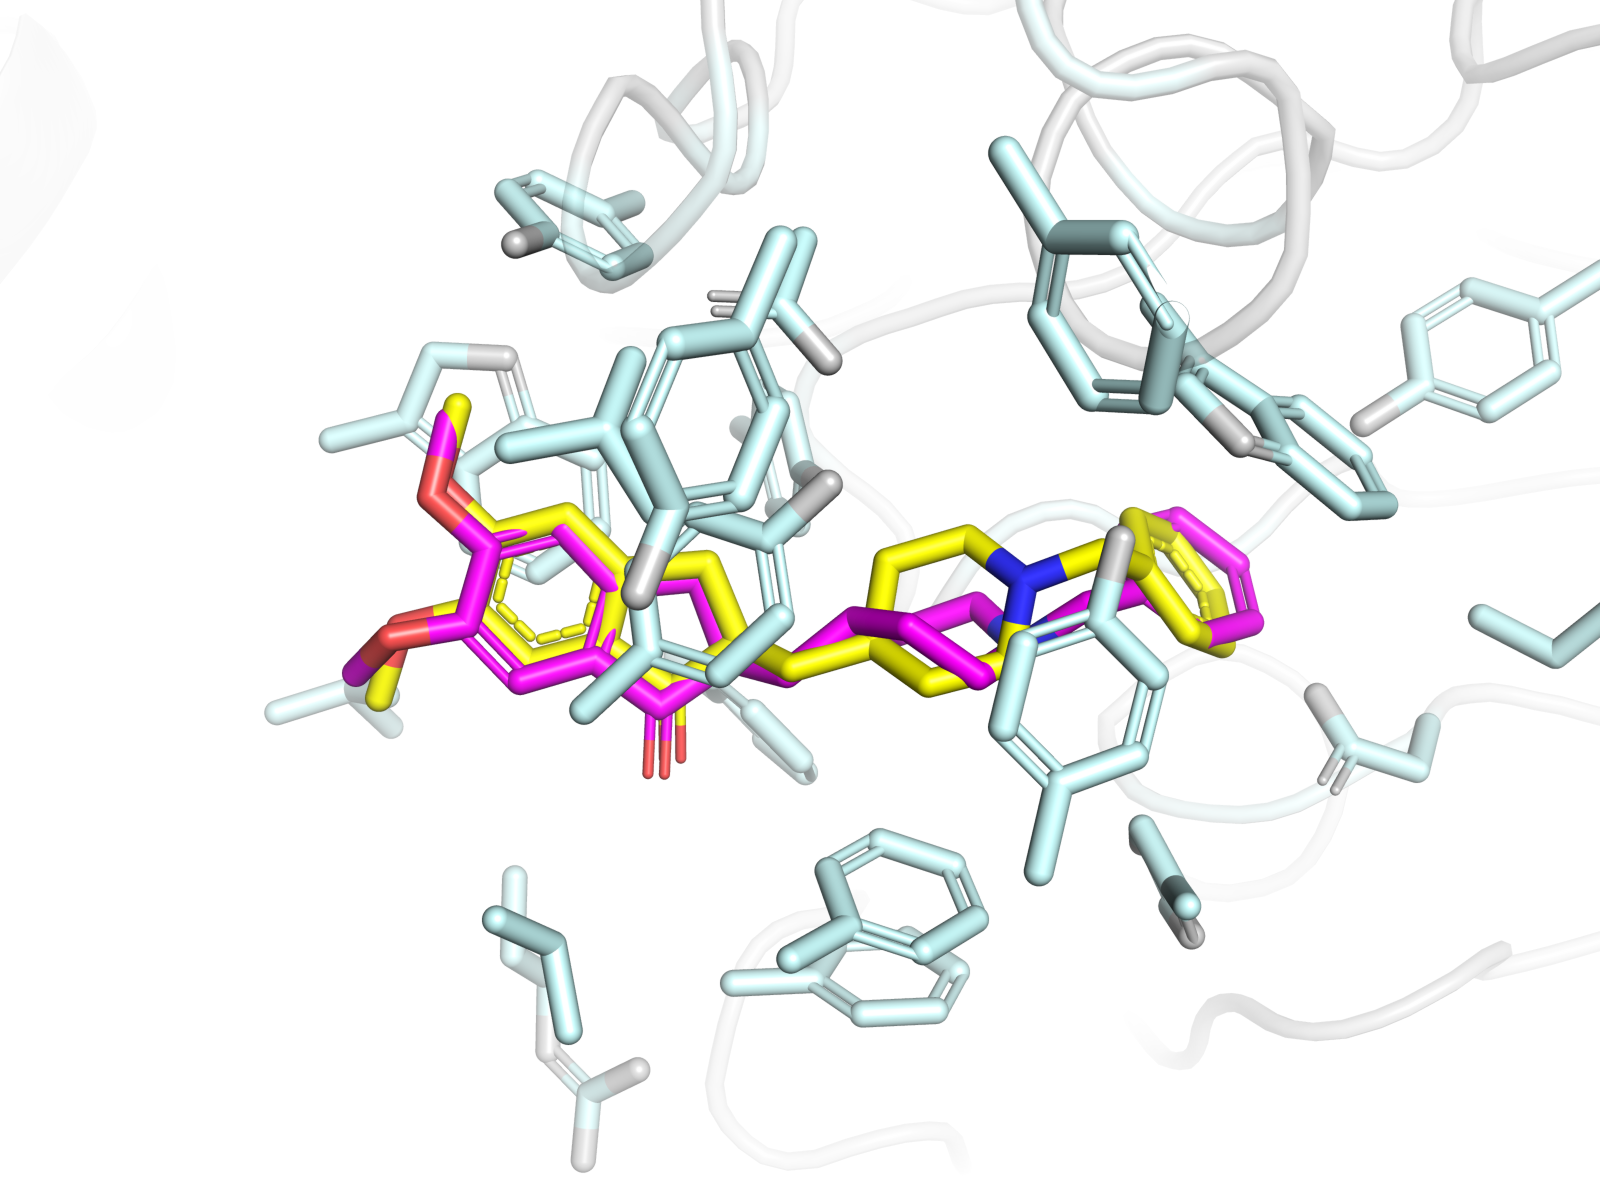

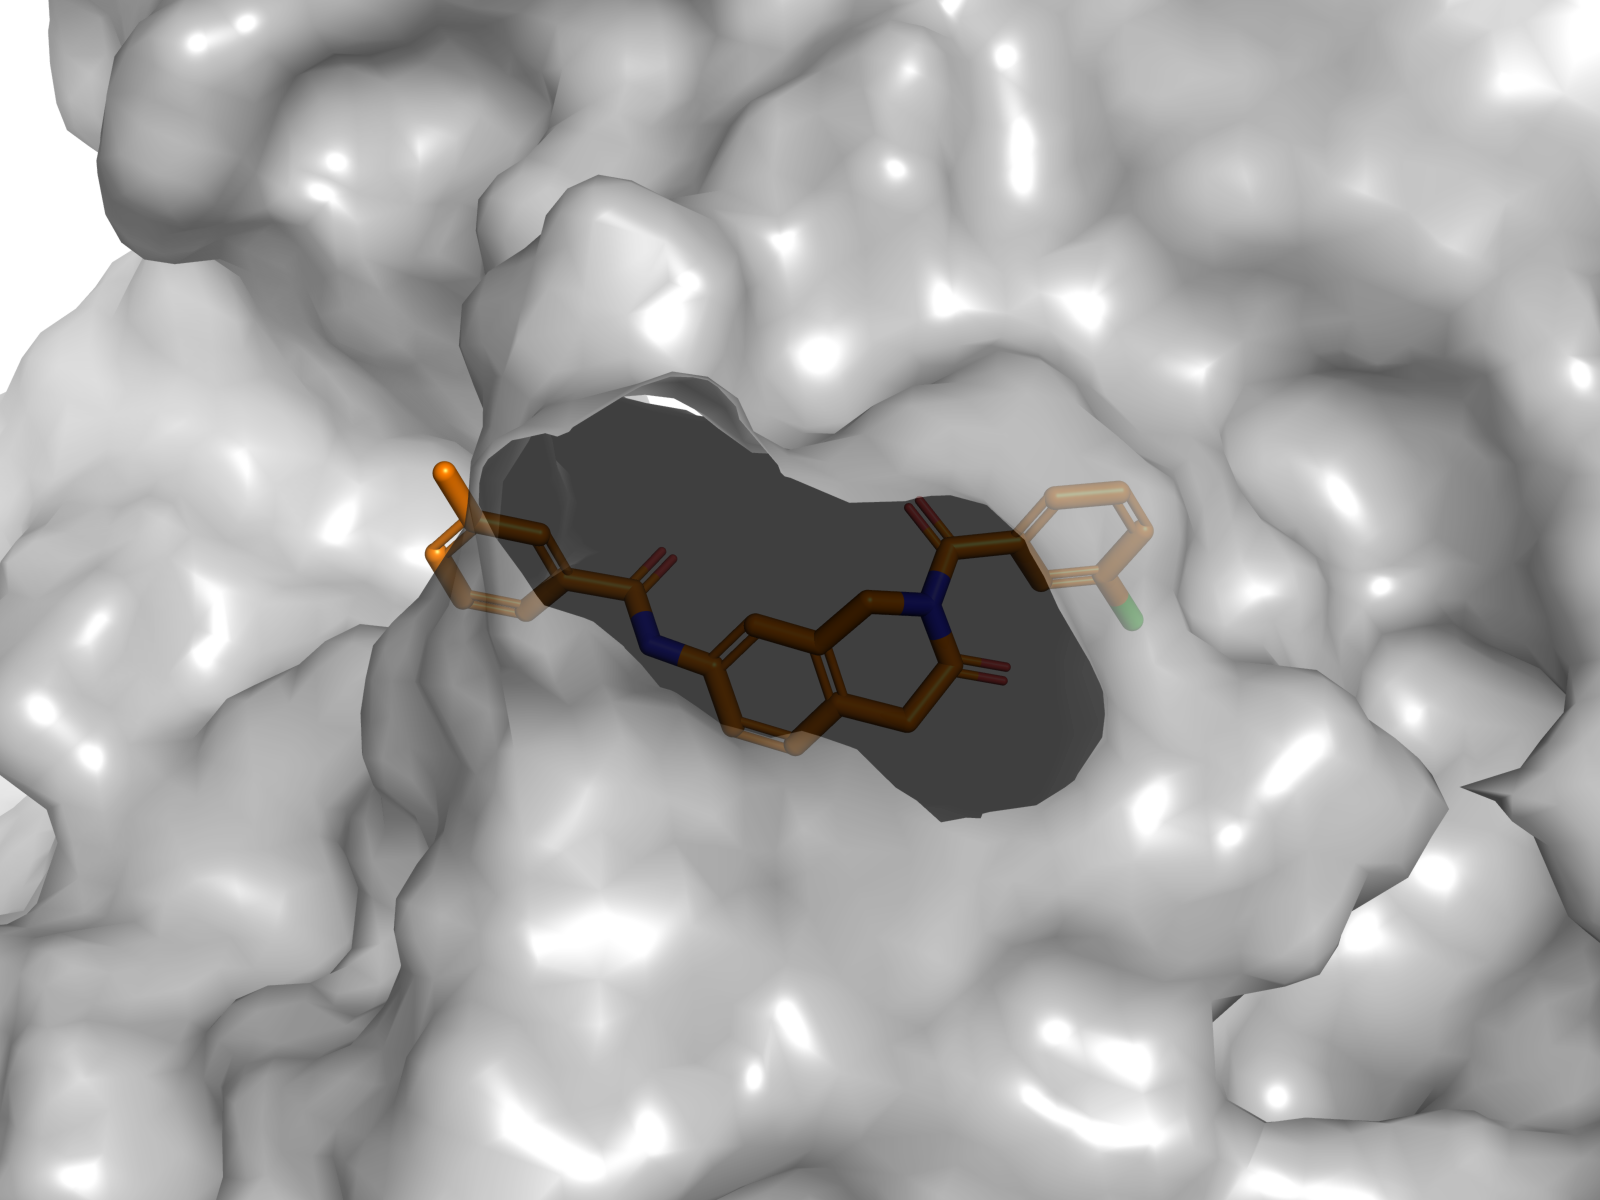

In [22]:
open("tophit.pml", "w").write("""
load receptor_prep.pdb, rec
load poses/CHEMBL4214707.sdf, hit
hide everything
bg_color white
show surface, rec
color grey70, rec
set transparency, 0.25
show sticks, hit and not hydro
color orange, hit and elem C
set ray_shadows, 0
set antialias, 2
orient hit
zoom hit, 6
png fig_tophit.png, width=1600, height=1200, dpi=300, ray=1
""")
!conda run -n dock pymol -cq tophit.pml

from IPython.display import Image, display
display(Image("fig_redock.png", width=700))
display(Image("fig_tophit.png", width=700))

COMPND    receptor_raw.pdb
 CmdLoad: "" loaded as "rec".
 CmdLoad: "poses/CHEMBL4214707.sdf" loaded as "hit".
 Executive: Colored 8148 atoms and 1 object.
 Setting: transparency set to 0.25000.
 Executive: Colored 24 atoms.
 Setting: ray_shadow set to off.
 Setting: antialias set to 2.
 Ray: render time: 59.15 sec. = 60.9 frames/hour (59.15 sec. accum.).
 ScenePNG: wrote 1600x1200 pixel image to file "fig_tophit.png".
PyMOL>load receptor_prep.pdb, rec
PyMOL>load poses/CHEMBL4214707.sdf, hit
PyMOL>hide everything
PyMOL>bg_color white
PyMOL>show surface, rec
PyMOL>color grey70, rec
PyMOL>set transparency, 0.25
PyMOL>show sticks, hit and not hydro
PyMOL>color orange, hit and elem C
PyMOL>set ray_shadows, 0
PyMOL>set antialias, 2
PyMOL>orient hit
PyMOL>zoom hit, 6
PyMOL>png fig_tophit.png, width=1600, height=1200, dpi=300, ray=1


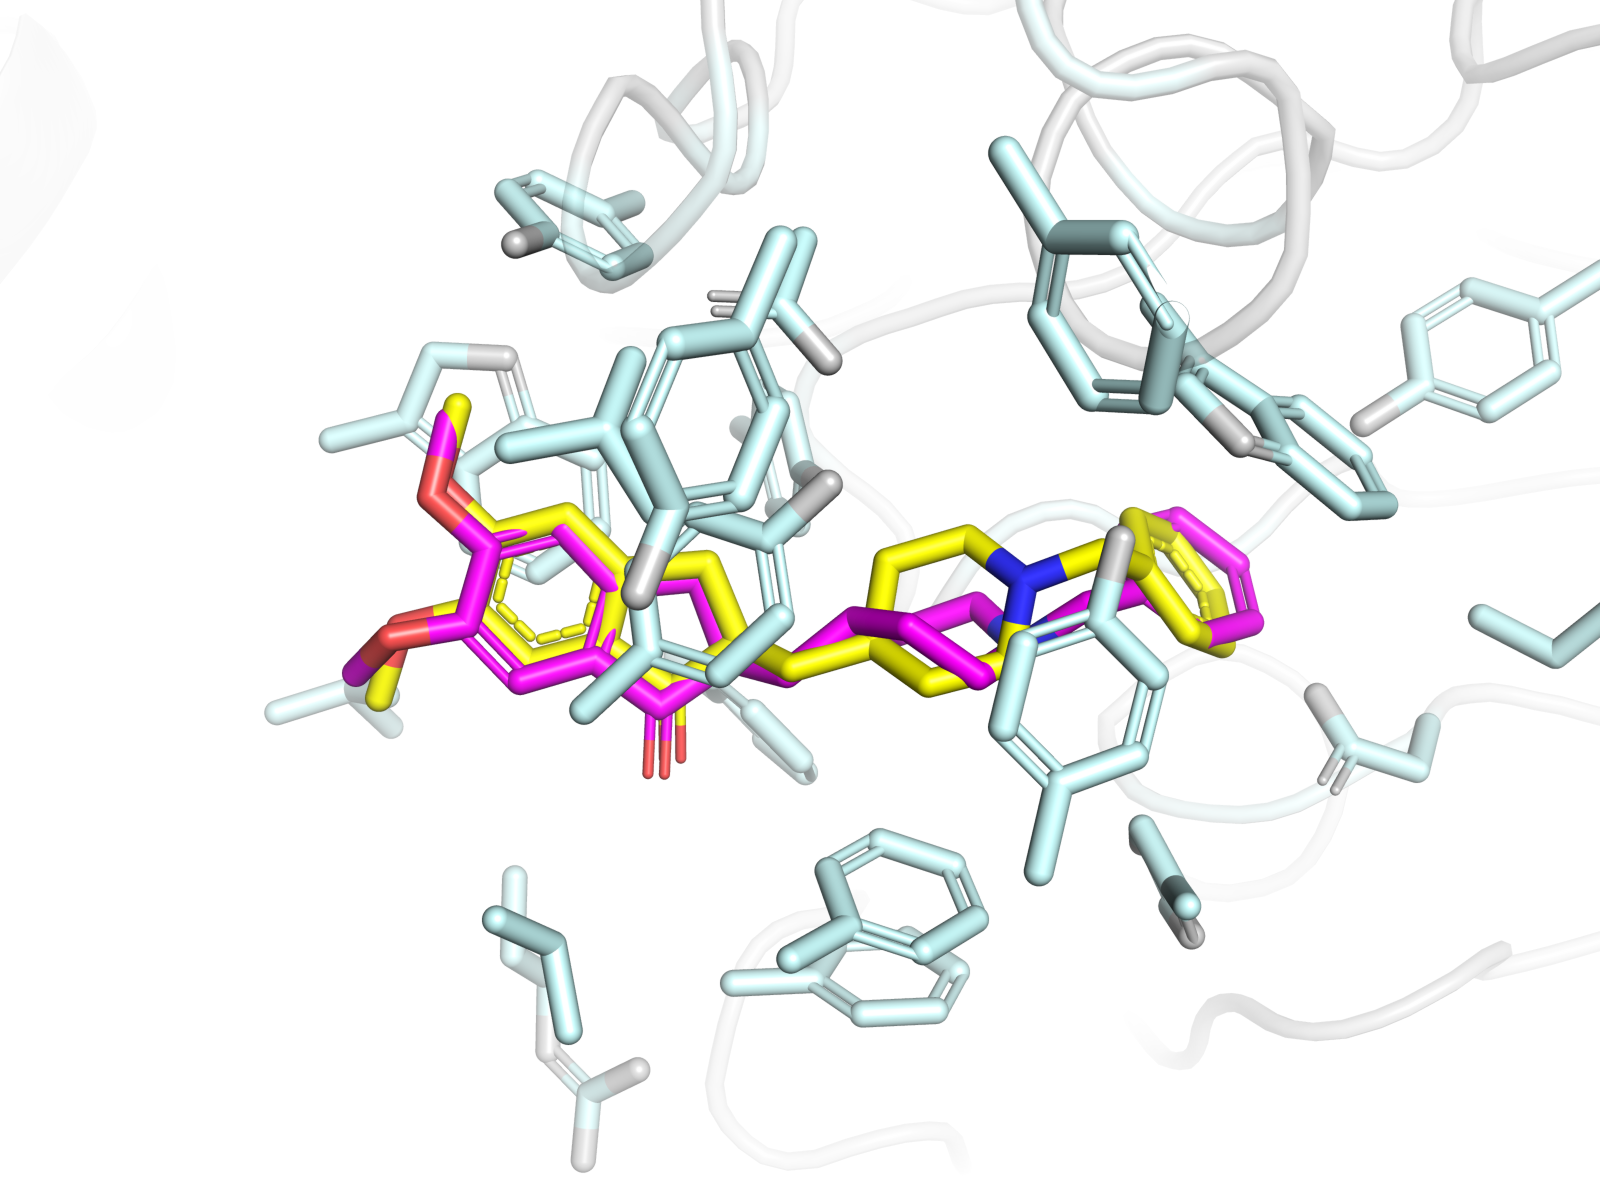

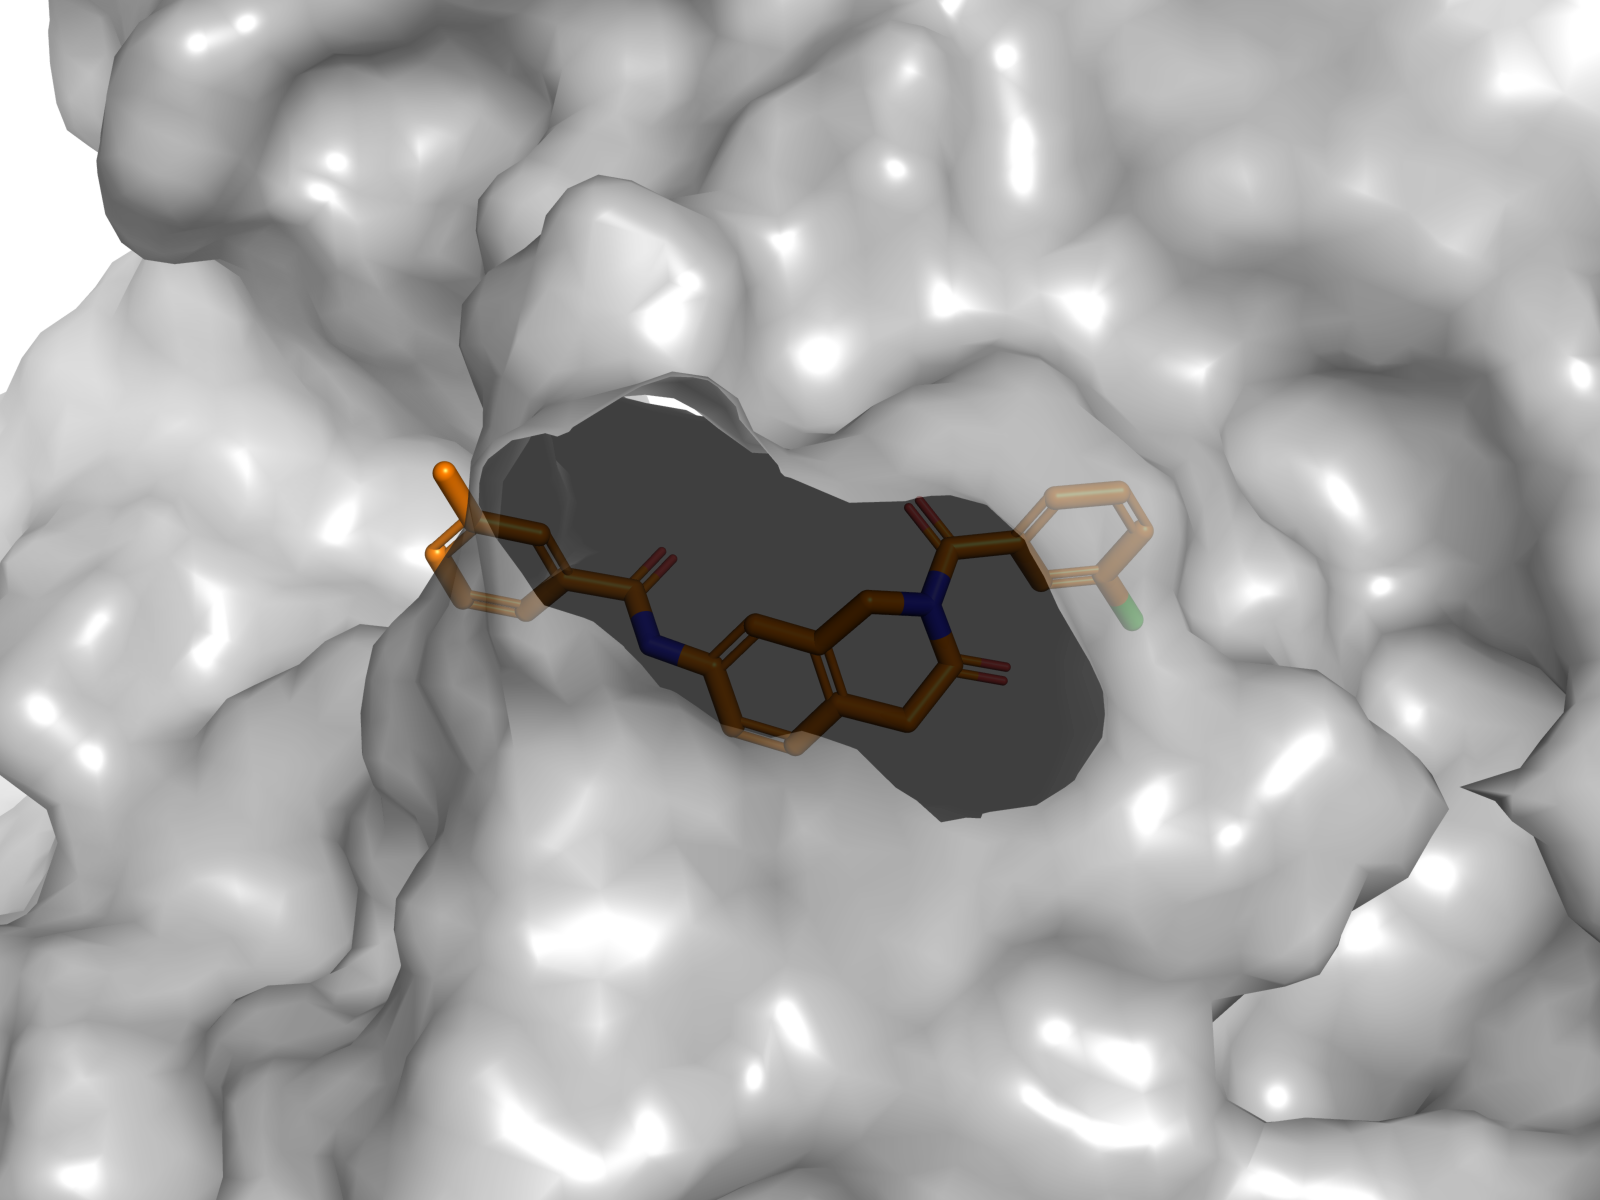

In [23]:
open("tophit.pml", "w").write("""
load receptor_prep.pdb, rec
load poses/CHEMBL4214707.sdf, hit
hide everything
bg_color white
show surface, rec
color grey70, rec
set transparency, 0.25
show sticks, hit and not hydro
color orange, hit and elem C
set ray_shadows, 0
set antialias, 2
orient hit
zoom hit, 6
png fig_tophit.png, width=1600, height=1200, dpi=300, ray=1
""")
!conda run -n dock pymol -cq tophit.pml

from IPython.display import Image, display
display(Image("fig_redock.png", width=700))
display(Image("fig_tophit.png", width=700))

COMPND    receptor_raw.pdb
 CmdLoad: "" loaded as "rec".
 CmdLoad: "poses/CHEMBL4214707.sdf" loaded as "hit".
 Executive: Colored 8148 atoms and 1 object.
 Setting: two_sided_lighting set to 1.
 Setting: ray_interior_color set to grey50.
 Setting: transparency set to 0.15000.
 Executive: Colored 24 atoms.
 Setting: ray_shadow set to off.
 Setting: antialias set to 2.
 Ray: render time: 49.17 sec. = 73.2 frames/hour (49.17 sec. accum.).
 ScenePNG: wrote 1600x1200 pixel image to file "fig_tophit.png".
PyMOL>load receptor_prep.pdb, rec
PyMOL>load poses/CHEMBL4214707.sdf, hit
PyMOL>hide everything
PyMOL>bg_color white
PyMOL>show surface, rec
PyMOL>color grey70, rec
PyMOL>set two_sided_lighting, on
PyMOL>set ray_interior_color, grey50
PyMOL>set transparency, 0.15
PyMOL>show sticks, hit and not hydro
PyMOL>color orange, hit and elem C
PyMOL>set ray_shadows, 0
PyMOL>set antialias, 2
PyMOL>orient hit
PyMOL>zoom hit, 6
PyMOL>png fig_tophit.png, width=1600, height=1200, dpi=300, ray=1


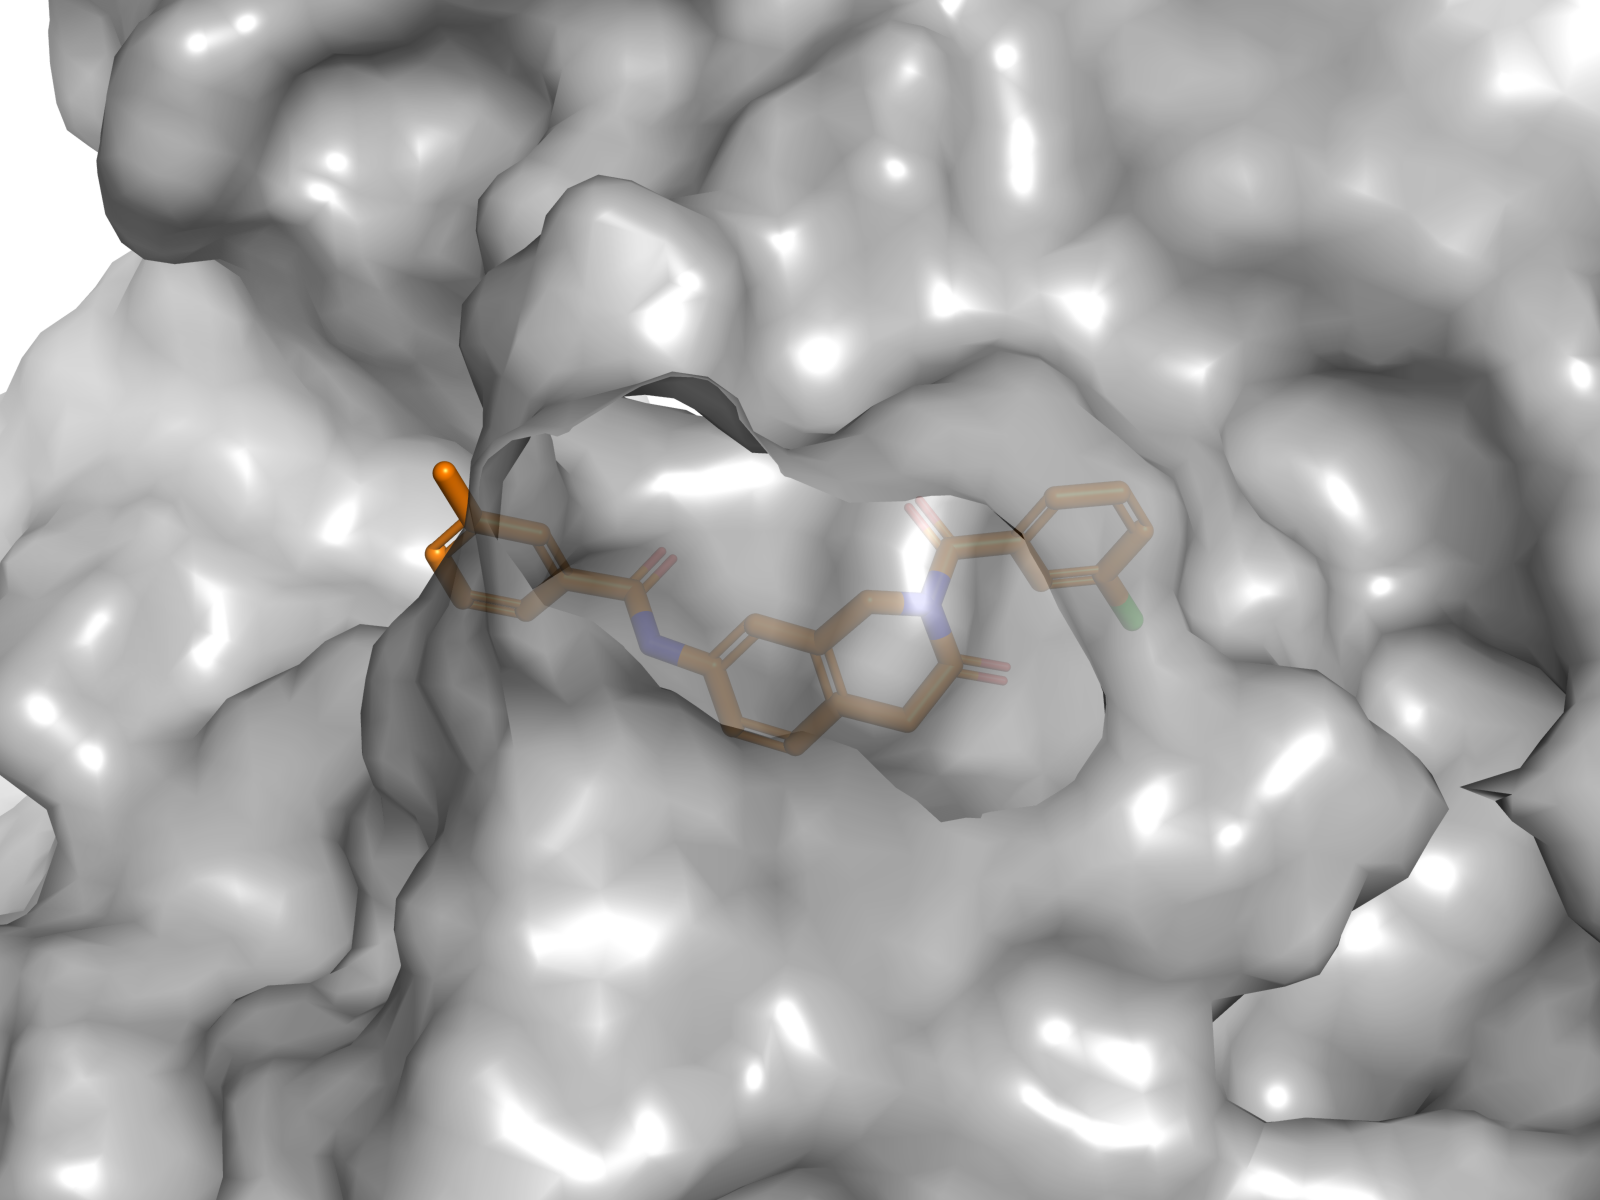

In [24]:
open("tophit.pml", "w").write("""
load receptor_prep.pdb, rec
load poses/CHEMBL4214707.sdf, hit
hide everything
bg_color white
show surface, rec
color grey70, rec
set two_sided_lighting, on
set ray_interior_color, grey50
set transparency, 0.15
show sticks, hit and not hydro
color orange, hit and elem C
set ray_shadows, 0
set antialias, 2
orient hit
zoom hit, 6
png fig_tophit.png, width=1600, height=1200, dpi=300, ray=1
""")
!conda run -n dock pymol -cq tophit.pml
from IPython.display import Image, display
display(Image("fig_tophit.png", width=700))